In [1]:
# Suppress KMeans parallelism warning
import os
os.environ['OMP_NUM_THREADS'] = '1'

# Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

# Data exploration
Load the dataset and examine its structure, check for missing values, and understand the basic statistics.

In [3]:
df = pd.read_csv('CA2_Dataset/CA2-Customer-Data.csv')
df.head()

,CustomerID,Gender,Age,Income (k$),How Much They Spend
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   CustomerID           200 non-null    int64 
 1   Gender               200 non-null    object
 2   Age                  200 non-null    int64 
 3   Income (k$)          200 non-null    int64 
 4   How Much They Spend  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


- No missing values in the dataset (200 non-null for all columns)
- Data types are appropriate (int64 for numerical, object for Gender)

In [5]:
display(df.describe())
print(f"Duplicates: {df.duplicated().sum()}")

,CustomerID,Age,Income (k$),How Much They Spend
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Duplicates: 0


- Age ranges from 18 to 70 (mean ~39)
- Income ranges from 15k to 137k (mean ~61k)
- Spending ranges from 1 to 99 (mean ~50) in dollars ($)

### Check proportion of male and female customers

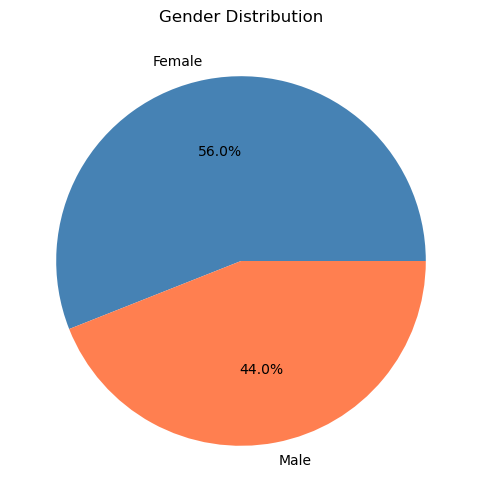

In [6]:
gender_counts = df['Gender'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', colors=['steelblue', 'coral'])
plt.title('Gender Distribution')
plt.show()

### Distribution of Age, income and spending

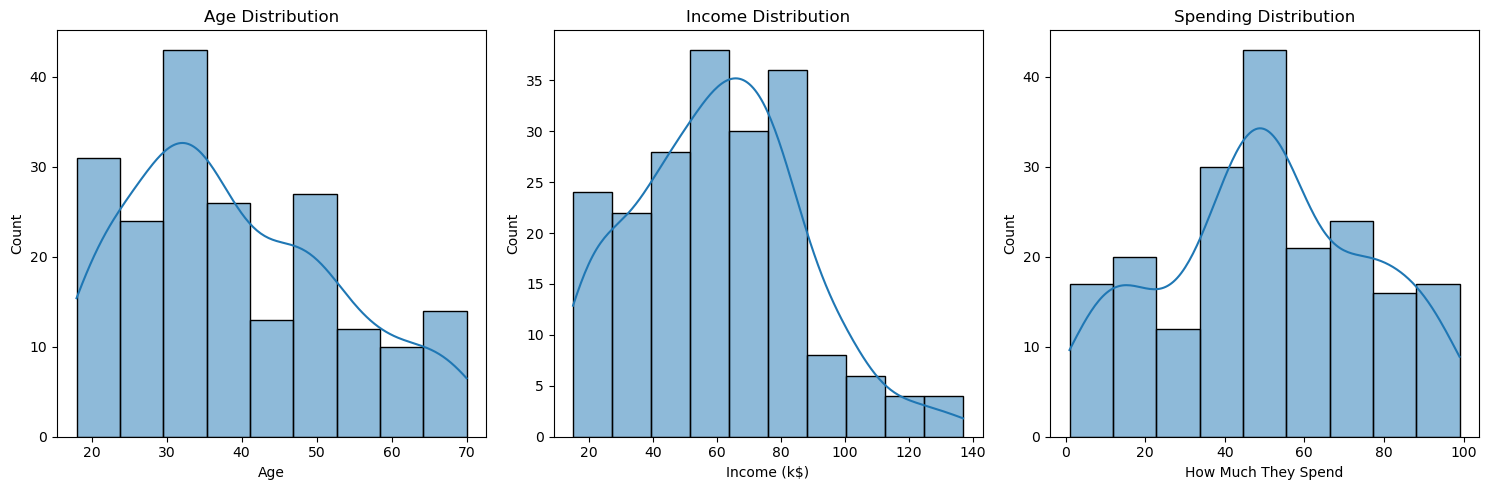

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.histplot(df['Age'], ax=axes[0], kde=True)
axes[0].set_title('Age Distribution')

sns.histplot(df['Income (k$)'], ax=axes[1], kde=True)
axes[1].set_title('Income Distribution')

sns.histplot(df['How Much They Spend'], ax=axes[2], kde=True)
axes[2].set_title('Spending Distribution')

plt.tight_layout()
plt.show()

### Outlier Check
- one potential outlier in Income at ~137k
- valid high-income customer, not a data error - no removal needed

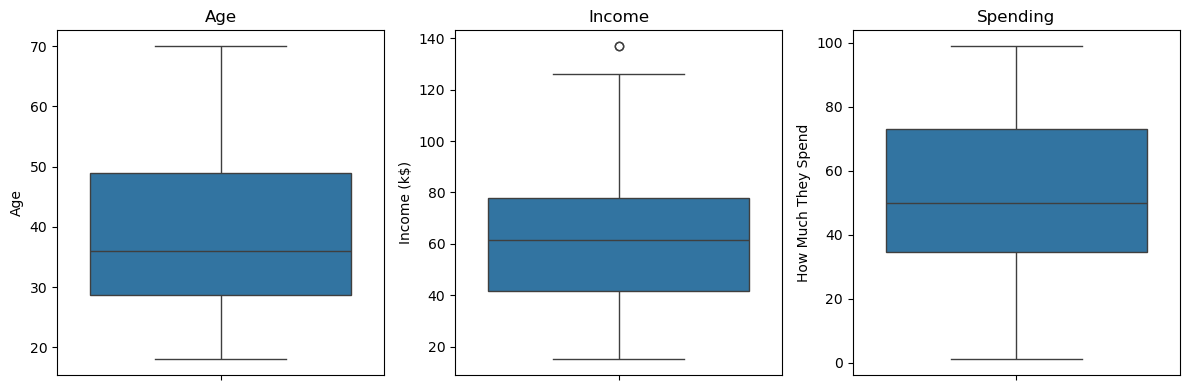

In [8]:
# Check for outliers using IQR method
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.boxplot(y=df['Age'], ax=axes[0])
axes[0].set_title('Age')
sns.boxplot(y=df['Income (k$)'], ax=axes[1])
axes[1].set_title('Income')
sns.boxplot(y=df['How Much They Spend'], ax=axes[2])
axes[2].set_title('Spending')
plt.tight_layout()
plt.show()

### Feature Relationships
Examine relationships between features to identify potential patterns for clustering.

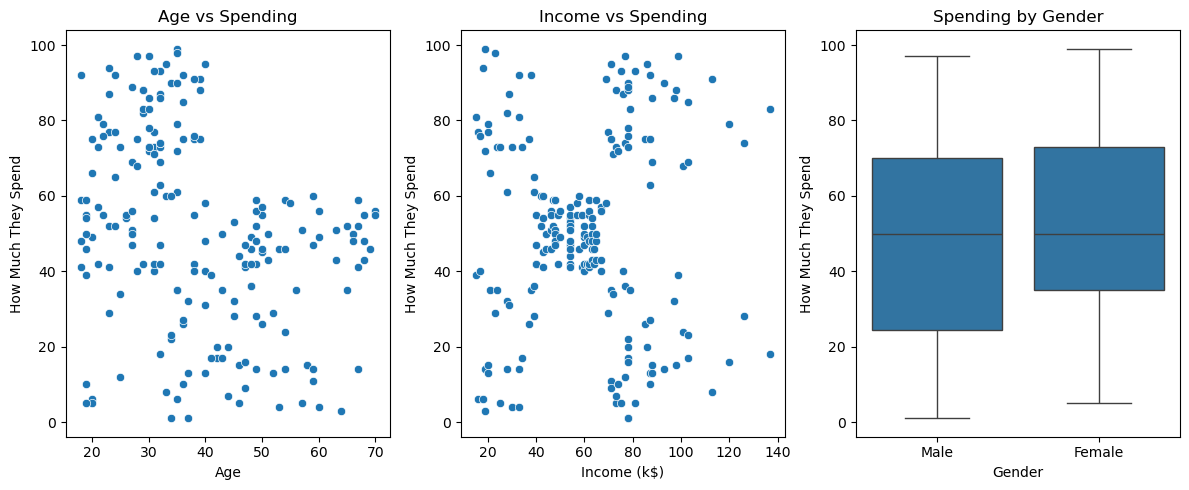

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

# age vs spending
sns.scatterplot(x='Age', y='How Much They Spend', data=df, ax=axes[0])
axes[0].set_title('Age vs Spending')

# income vs spending
sns.scatterplot(x='Income (k$)', y='How Much They Spend', data=df, ax=axes[1])
axes[1].set_title('Income vs Spending')

# check distribution of spending by gender
sns.boxplot(x='Gender', y='How Much They Spend', data=df, ax = axes[2])
axes[2].set_title('Spending by Gender')

plt.tight_layout()
plt.show()

### Correlation analysis
See if there a is correlation, eg if one feature goes up the other goes up, and if one feature goes down the other goes down

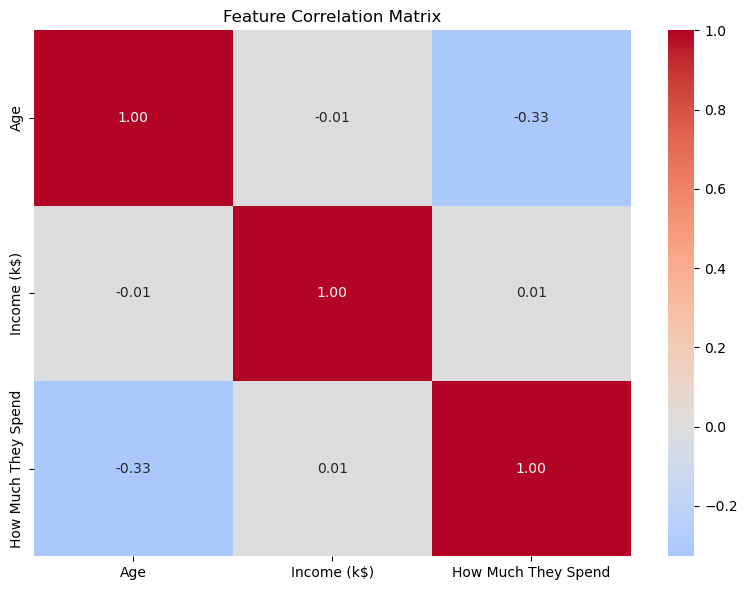

In [10]:
plt.figure(figsize=(8, 6))
corr = df[['Age', 'Income (k$)', 'How Much They Spend']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

# Insights
### Income vs Spending
- Higher income does not equal to higher spending
- The group at around 60k has a very consistent spending of around 40 to 60 dollars
- Low income does not equal to low spending and in some cases even very high spending

### Age vs spending
- no clear relationship
- younger customers tend to have those spending a lot and some very little
- older customers tend to spend less overall, having almost none above $60

### Histogram
- Age: Skewed younger, most customers are 25-40 years old, with lesser older customers
- Income: Roughly normal distribution at around 50-70k, with fewer high earners (100k+)
- Spending: around normal distribution with a peak around 40-60 dollars.

### Gender
- slightly more females (56%) than males (44%)
- gender does not affect spending (similar median, IQR, and range in boxplot)
- excluded from clustering features as it does not help distinguish customer groups

### Correlation Analysis
- Income vs Spending: 0.01: confirms what the scatter plot shows: the 5 distinct groups suggest spending behavior is driven by lifestyle/life stage, not just income level
- Age vs Spending: -0.33: weak negative correlation, older customers tend to spend less (visible in scatter plot where high spenders are mostly younger)
- Age vs Income: -0.01: no relationship, which is expected since income depends more on career than age alone

The weak correlations explain why simple linear analysis wouldn't capture these patterns — clustering is needed to identify the distinct customer segments.

# Data Preprocessing

### Feature Selection
- Dropped CustomerID (just an identifier, not useful for clustering)
- Excluded Gender (no significant difference in spending between genders)
- Selected Income and Spending as they show clear clustering patterns in the scatter plot

In [11]:
df_features = df[['Income (k$)', 'How Much They Spend']]

In [12]:
# Test if including Age improves clustering
features_no_age = df[['Income (k$)', 'How Much They Spend']]
features_with_age = df[['Age', 'Income (k$)', 'How Much They Spend']]

scaled_no_age = StandardScaler().fit_transform(features_no_age)
scaled_with_age = StandardScaler().fit_transform(features_with_age)

km_no_age = KMeans(n_clusters=5, random_state=42)
km_with_age = KMeans(n_clusters=5, random_state=42)

labels_no_age = km_no_age.fit_predict(scaled_no_age)
labels_with_age = km_with_age.fit_predict(scaled_with_age)

print(f"Without Age: {silhouette_score(scaled_no_age, labels_no_age):.4f}")
print(f"With Age:    {silhouette_score(scaled_with_age, labels_with_age):.4f}")

Without Age: 0.5547
With Age:    0.4085


Including Age reduces silhouette from 0.555 to 0.409 — Age adds noise to clustering. Age is excluded from clustering features but used for post-clustering analysis to interpret customer profiles.


### Feature Scaling
Apply StandardScaler to normalize the features. Even though Income (15-137) and Spending (1-99) have similar ranges, scaling ensures both features contribute equally to distance calculations in clustering.

In [13]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_features)

# Clustering

## Finding the best K

### Elbow Method
- plots inertia against different k values
- inertia is the sum of squared distances from each point to its cluster center
- look for the "elbow" where adding more clusters stops reducing inertia significantly

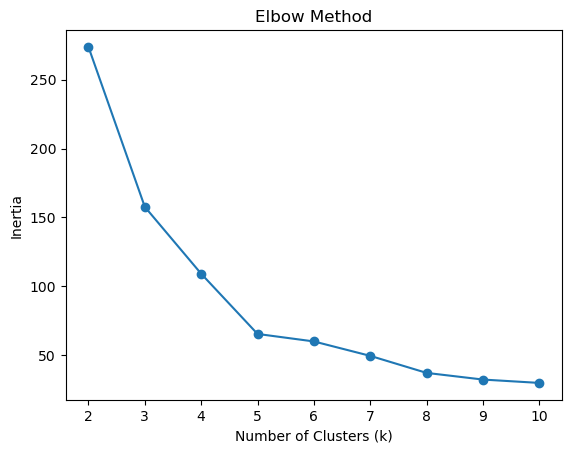

In [14]:
# 1. Find best k using elbow method
inertias = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(k_range, inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

### Silhouette score method
- measures how similar each point is to its own cluster compared to other clusters
- score ranges from -1 to 1, higher means better defined clusters
- pick k with the highest silhouette score

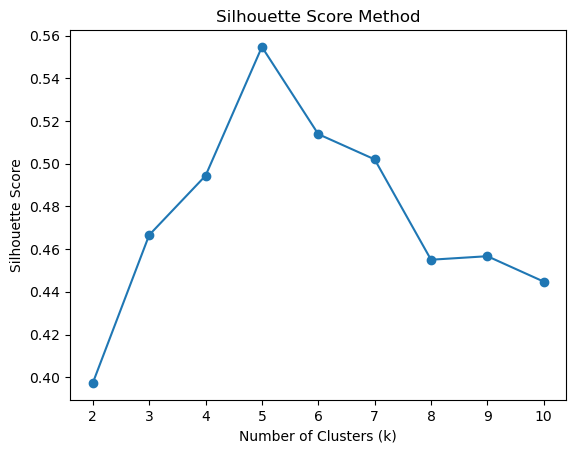

In [15]:
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df_scaled)
    silhouette_scores.append(silhouette_score(df_scaled, labels))

plt.plot(k_range, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Method')
plt.show()

## Best K
based on elbow method and silhouette score, both agrees that best k is at 5, the best number of clusters is at 5.

## K-Means clustering
- uses centroids to assign each point to nearest cluster
- random_state=42 for reproducibility
- using k = 5 based on elbow and silhouette methods

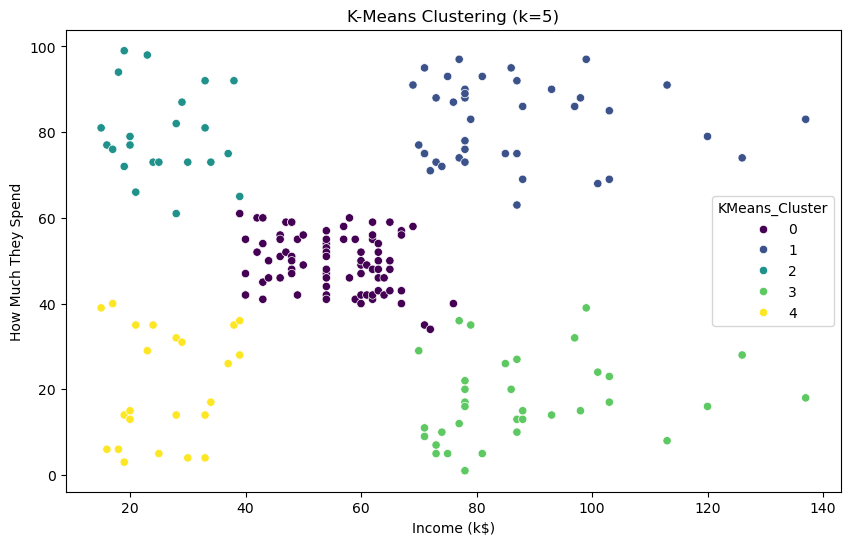

In [16]:
# Fit K-Means with optimal k
kmeans = KMeans(n_clusters=5, random_state=42) # random_state for consistency
df['KMeans_Cluster'] = kmeans.fit_predict(df_scaled)

# Visualize clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Income (k$)', y='How Much They Spend', hue='KMeans_Cluster', data=df, palette='viridis')
plt.title('K-Means Clustering (k=5)')
plt.show()

## Agglomerative clustering
- hierarchical clustering that builds clusters by merging points step by step
- uses ward linkage to minimize variance within clusters
- using k = 5 for comparison with K-Means


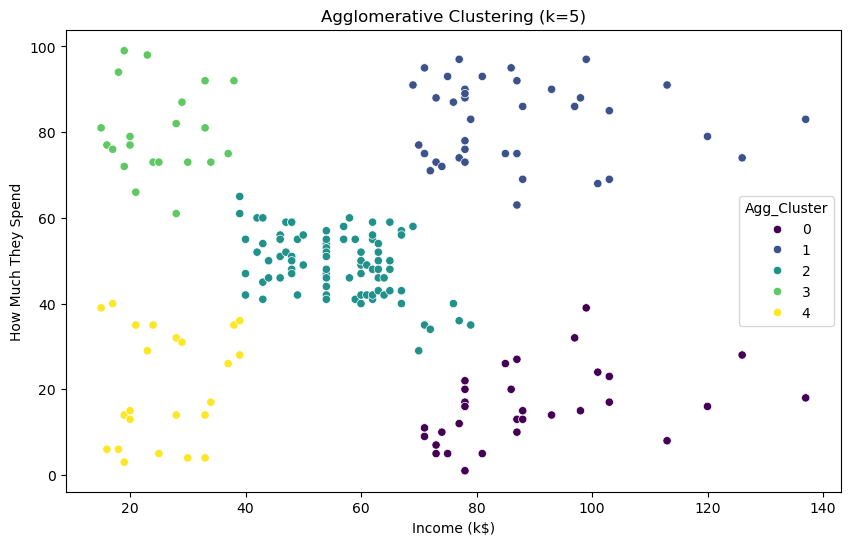

In [17]:
# Agglomerative Clustering with k=5
agg_clustering = AgglomerativeClustering(n_clusters=5)
df['Agg_Cluster'] = agg_clustering.fit_predict(df_scaled)

# Visualize clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Income (k$)', y='How Much They Spend', hue='Agg_Cluster', data=df, palette='viridis')
plt.title('Agglomerative Clustering (k=5)')
plt.show()

### Dendrogram
- visualizes the hierarchical structure of how customers are grouped
- cutting at distance 5 (red dashed line) gives 5 clusters, supporting our choice of k = 5

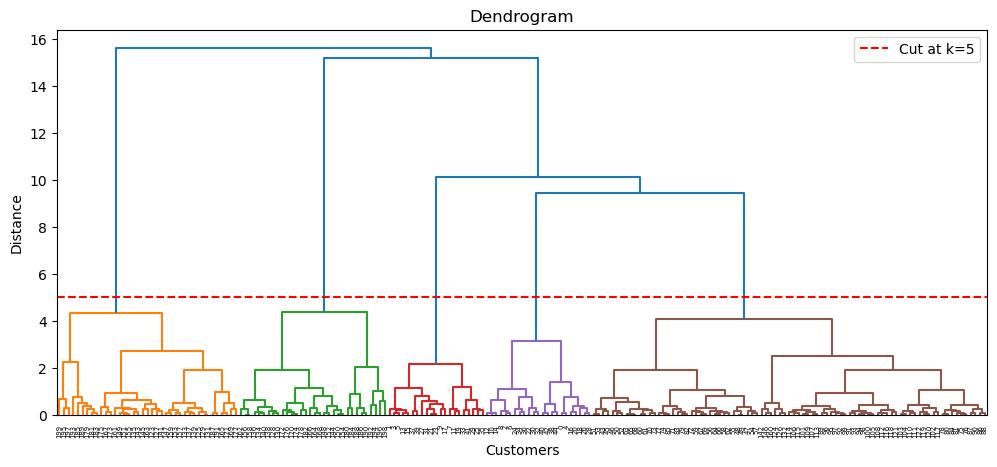

In [18]:
from scipy.cluster.hierarchy import dendrogram, linkage

plt.figure(figsize=(12, 5))
linkage_matrix = linkage(df_scaled, method='ward')
dendrogram(linkage_matrix, color_threshold=5)
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Distance')
plt.axhline(y=5, color='r', linestyle='--', label='Cut at k=5')
plt.legend()
plt.show()

# Results Analysis

## Cluster Characteristics
Examine the average Income and Spending for each cluster to understand what type of customers are in each group.

In [19]:
print(df.groupby('KMeans_Cluster')[['Income (k$)', 'How Much They Spend']].mean())
print(df['KMeans_Cluster'].value_counts().sort_index())

                Income (k$)  How Much They Spend
KMeans_Cluster                                  
0                 55.296296            49.518519
1                 86.538462            82.128205
2                 25.727273            79.363636
3                 88.200000            17.114286
4                 26.304348            20.913043
KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [20]:
print(df.groupby('Agg_Cluster')[['Income (k$)', 'How Much They Spend']].mean())

             Income (k$)  How Much They Spend
Agg_Cluster                                  
0              89.406250            15.593750
1              86.538462            82.128205
2              55.811765            49.129412
3              25.095238            80.047619
4              26.304348            20.913043


### Algorithm Comparison
- both K-Means and Agglomerative produce very similar clusters
- using two different algorithms (centroid-based vs hierarchical) validates that the 5 clusters are real patterns in the data, not artifacts of one method

## Additional Feature Analysis
Check if Age and Gender show any patterns within clusters.

In [21]:
print(df.groupby('KMeans_Cluster')[['Age', 'Income (k$)', 'How Much They Spend']].mean())

                      Age  Income (k$)  How Much They Spend
KMeans_Cluster                                             
0               42.716049    55.296296            49.518519
1               32.692308    86.538462            82.128205
2               25.272727    25.727273            79.363636
3               41.114286    88.200000            17.114286
4               45.217391    26.304348            20.913043


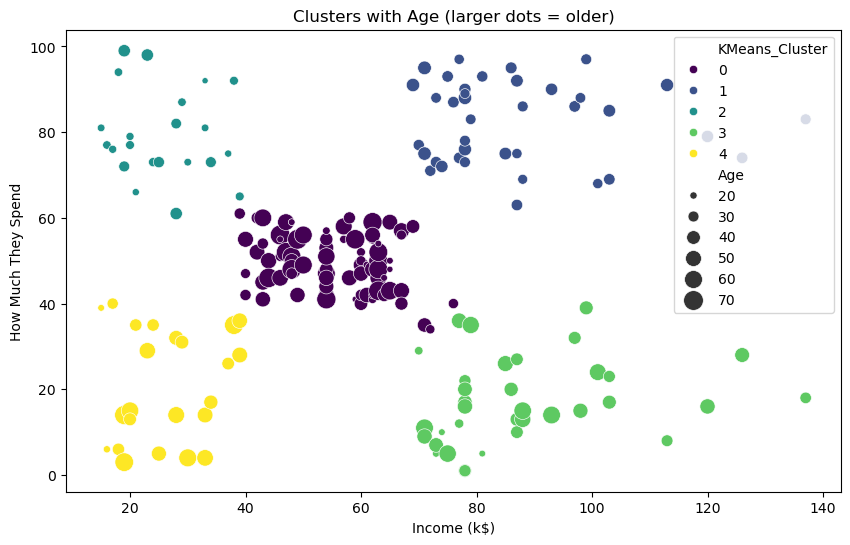

In [22]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Income (k$)', y='How Much They Spend', hue='KMeans_Cluster', size='Age', data=df, palette='viridis', sizes=(20, 200))
plt.title('Clusters with Age (larger dots = older)')
plt.show()

In [23]:
# crosstab to see gender distribution across clusters
print(pd.crosstab(df['KMeans_Cluster'], df['Gender']))

Gender          Female  Male
KMeans_Cluster              
0                   48    33
1                   21    18
2                   13     9
3                   16    19
4                   14     9


### Age Patterns
Each cluster has a distinct age profile that helps explain their spending behavior:

**Cluster 2 (~ 25 years, low income, high spending):**
- youngest customers, likely students or early career
- fewer financial responsibilities (no mortgage, no kids, possibly living with parents)
- prioritize lifestyle and experiences over saving

**Cluster 1 (~ 33 years, high income, high spending):**
- young professionals with established careers
- high earning power and willing to spend it
- still relatively few responsibilities compared to older groups

**Cluster 3 (~ 41 years, high income, low spending):**
- middle-aged with high income but barely spending
- likely have financial responsibilities (mortgage, kids education, retirement savings)
- financially disciplined, prioritize saving over spending

**Cluster 0 (~ 43 years, middle income, moderate spending):**
- largest group, represents the "average" customer
- balanced lifestyle with moderate income and spending

**Cluster 4 (~ 45 years, low income, low spending):**
- oldest group with limited income
- budget-conscious out of necessity
- careful and conservative with spending

**Pattern:** Younger customers (25-33) tend to be high spenders regardless of income. Older customers (41-45) tend to be low spenders even when they have high income. This suggests spending habits are influenced by life stage and responsibilities, not just income level.


### Gender Patterns
- gender is fairly evenly distributed across all clusters
- confirms gender does not significantly affect spending behavior

### Model Evaluation

In [24]:
print("K-Means:", silhouette_score(df_scaled, df['KMeans_Cluster']))
print("Agglomerative:", silhouette_score(df_scaled, df['Agg_Cluster']))

K-Means: 0.5546571631111091
Agglomerative: 0.5538089226688662


- K-Means silhouette score: 0.555
- Agglomerative silhouette score: 0.554
- both algorithms perform equally well
- score of ~0.55 indicates reasonably well-defined clusters (above 0.5 is generally considered good, 1.0 is perfect)

# Conclusion

## Answers to Questions

### 1. How to perform customer segmentation using unsupervised ML in Python?
- use scikit-learn's KMeans and AgglomerativeClustering
- select relevant features (Income, Spending) based on EDA
- scale the data using StandardScaler
- determine optimal k using elbow method and silhouette score
- fit the model and assign cluster labels
- analyze clusters by examining additional features like Age and Gender

### 2. What are the characteristics of each customer cluster?
| Cluster | Age | Income | Spending ($) | Count | Profile |
|---------|-----|--------|----------|-------|---------|
| 0 | ~43 | ~55k | ~50 | 81 | Average customers - balanced lifestyle |
| 1 | ~33 | ~87k | ~82 | 39 | Young professionals - high earners who enjoy spending |
| 2 | ~25 | ~26k | ~79 | 22 | Young spenders - low income but high spending |
| 3 | ~41 | ~88k | ~17 | 35 | Wealthy savers - high income but very conservative |
| 4 | ~45 | ~26k | ~21 | 23 | Budget-conscious - low income, careful spending |

**Key finding:** Younger customers (25-33) are high spenders regardless of income, while older customers (41-45) spend less even with high income. Life stage and responsibilities appear to influence spending more than income alone.

### 3. Which group of customers needs more attention?

**Cluster 3 (Wealthy savers - ~41 years, ~88k income, ~$17 spending):**
- high income but barely spending - untapped potential
- likely saving for mortgage, kids education, or retirement
- **Strategy:** target with quality/value messaging, family-oriented promotions, premium products with long-term value since they won't respond to impulse deals

**Cluster 2 (Young spenders - ~25 years, ~26k income, ~$79 spending):**
- spending heavily despite low income - valuable but risky
- young with fewer responsibilities, prioritizing lifestyle
- **Strategy:** loyalty programs to retain them, installment plans, social media marketing targeting younger audiences and they could be future Cluster 1 customers as their income grows